<!-- d2l:prose id=samplers-md-1 fw=all -->

# Samplers, Inversion and Editing

Every step of a diffusion sampler evaluates the score or velocity network once, so the computational cost of generating an image scales linearly with the number of steps. In that section, 50 Euler steps of the probability-flow ODE approached the Fréchet distance (FD) of the 1,000-step ancestral chain at one-twentieth the cost. Because the training regression of that section depends only on the marginal distributions of $\mathbf{x}_t$ at single time points $t$ rather than on multi-step joint distributions, a single trained network supports a continuous family of stochastic and deterministic reverse processes [@Song.Meng.Ermon.2020].

In this section we derive the *denoising diffusion implicit model* (DDIM) family, show that its deterministic member ($\eta = 0$) coincides with Euler's method on the probability-flow ODE in $(\bar{\mathbf{x}}, \bar\sigma)$ coordinates, and compare first-order (Euler/DDIM), second-order (Heun), and multistep (Adams--Bashforth / DPM-Solver++) solvers across step budgets and time grids. Finally, we use the invertibility of the deterministic ODE for image-to-noise inversion, latent interpolation, partial-noising edits, and zero-shot inpainting.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
torch.set_float32_matmul_precision('high')  # tf32 matmuls on tensor cores

<!-- d2l:prose id=samplers-md-2 fw=all -->

## Deterministic and Stochastic Samplers

The two samplers of that section, the ancestral
chain and Euler's method, read the network in the same way, although one
adds fresh noise at every step and the other none. At a point
$\mathbf{x}_t = \alpha_t \mathbf{x}_0 + \sigma_t \boldsymbol\epsilon$ of a
Gaussian path the network gives an estimate $\hat{\mathbf{x}}_0$ of the
clean point and an estimate $\hat{\boldsymbol\epsilon}$ of the noise, and
each determines the other:

$$\hat{\mathbf{x}}_0 = \frac{\mathbf{x}_t - \sigma_t \hat{\boldsymbol\epsilon}}{\alpha_t}.$$

Whatever the network was trained to predict, `d2l.make_pred` of
that section turns it into a function `pred(x,
alpha, sigma)` returning this pair at any noise level, and the samplers of
this section read nothing else.

### The DDIM Family and Euler's Method

Take a time $t$ and an earlier time $s < t$. A sampler step from $t$ to $s$
must turn a point distributed like $\mathbf{x}_t$ into one distributed like
$\mathbf{x}_s$; the regression constrains nothing else. Write $\mathbf{x}_t
= \alpha_t \mathbf{x}_0 + \sigma_t \boldsymbol\epsilon$, choose a noise
scale $\tilde\sigma$ between $0$ and $\sigma_s$, and set

$$\mathbf{x}_s = \alpha_s \mathbf{x}_0 + \sqrt{\sigma_s^2 - \tilde\sigma^2}\, \boldsymbol\epsilon + \tilde\sigma\, \boldsymbol\xi, \qquad \boldsymbol\xi \sim \mathcal{N}(\mathbf{0}, \mathbf{I}),$$

with $\boldsymbol\xi$ independent of $\boldsymbol\epsilon$. The two noise
variances add to $\sigma_s^2$, so given $\mathbf{x}_0$ the point
$\mathbf{x}_s$ has its correct distribution for every $\tilde\sigma$, and
since $\boldsymbol\epsilon = (\mathbf{x}_t - \alpha_t \mathbf{x}_0) /
\sigma_t$, each $\tilde\sigma$ defines a step from $\mathbf{x}_t$ to
$\mathbf{x}_s$. A sampler uses the network's estimates in place of
$\mathbf{x}_0$ and $\boldsymbol\epsilon$:

$$\mathbf{x}_s = \alpha_s \hat{\mathbf{x}}_0 + \sqrt{\sigma_s^2 - \tilde\sigma^2}\, \hat{\boldsymbol\epsilon} + \tilde\sigma\, \boldsymbol\xi.$$

The step moves the predicted clean point to level $s$ together with the
predicted noise, and replaces part of that noise by fresh noise.
@Song.Meng.Ermon.2020 measure the fresh part by a strength
$\eta \geq 0$,

$$\tilde\sigma = \eta\, \sigma_s \sqrt{1 - \kappa^2}, \qquad \kappa = \frac{\sigma_s \alpha_t}{\alpha_s \sigma_t}.$$

Here $\kappa^2 = \mathrm{SNR}_t / \mathrm{SNR}_s < 1$, with $\mathrm{SNR} =
\alpha^2 / \sigma^2$. At $\eta = 1$, $\tilde\sigma^2$ is the variance of
$\mathbf{x}_s$ given $\mathbf{x}_t$ and $\mathbf{x}_0$ under the noising
chain of that section (Exercise
1). The step then samples that chain's
posterior, with the estimates in place of the truth. At $\eta = 0$ no fresh
noise enters and the step is deterministic. This is the *denoising diffusion
implicit model* (DDIM), called implicit because it defines its samples by a
map from noise rather than by a chain of densities.

`ddim_sample` runs the DDIM family on the grid of `path.grid` with any
predictor `pred(x, alpha, sigma) -> (x0, eps)`, stopping at `t_end` (data by
default) so that a loop can act on the sample between levels.

In [3]:
@torch.no_grad()
def ddim_sample(pred, x, path, steps, eta=0.0, *, t_start=1.0, t_end=0.0):
    """DDIM from x at t_start (1 is noise) to t_end; eta = 0 is deterministic.
    eta = 1 draws the posterior variance: not the ancestral sampler's."""
    a, s = path.grid(steps, t_start, t_end)
    for i in range(steps):
        x0, eps = pred(x, a[i], s[i])
        ratio = s[i + 1] * a[i] / (a[i + 1] * s[i])     # kappa of the text
        var = (eta * s[i + 1]) ** 2 * (1 - ratio ** 2)   # fresh noise
        x = a[i + 1] * x0 + math.sqrt(s[i + 1] ** 2 - var) * eps
        if var > 0:
            x = x + math.sqrt(var) * torch.randn_like(x)
    return x

<!-- d2l:prose id=samplers-md-3 fw=all -->

How large an error does a long deterministic stride make? Take data that are
themselves standard Gaussian, on the variance-preserving path. Then
$\mathbf{x}_t$ is standard Gaussian at every time, so the exact sampler
should move no point. The exact estimates are $\hat{\mathbf{x}}_0 = \alpha_t
\mathbf{x}_t$ and $\hat{\boldsymbol\epsilon} = \sigma_t \mathbf{x}_t$, and
one deterministic stride from $t = 1$ to $t = 0$ returns $\hat{\mathbf{x}}_0
= \alpha_1 \mathbf{x}_1$: with $\alpha_1 \approx 0.0066$ the whole cloud
collapses onto its mean. The step holds the noise estimate fixed across the
stride, while along the exact trajectory it changes.

At $\eta = 0$ the step is $\mathbf{x}_s = \alpha_s \hat{\mathbf{x}}_0 +
\sigma_s \hat{\boldsymbol\epsilon}$, the step that `ode_sample` takes in
that section. In the coordinates $\bar{\mathbf{x}} =
\mathbf{x} / \alpha_t$ and $\bar\sigma_t = \sigma_t / \alpha_t$ derived
there it reads

$$\bar{\mathbf{x}}_s = \bar{\mathbf{x}}_t + (\bar\sigma_s - \bar\sigma_t)\, \hat{\boldsymbol\epsilon},$$

one Euler step of the probability-flow ODE $d\bar{\mathbf{x}} / d\bar\sigma =
\hat{\boldsymbol\epsilon}$, and the ratio $\kappa$ above is simply
$\bar\sigma_s / \bar\sigma_t$. On every Gaussian path, then, DDIM is
Euler's method, and with $\eta = 0$ `ddim_sample` and `ode_sample` on the
same levels compute one function in two coordinate systems.
that section proves the equivalence, together with the two extreme cases: a single data point is
integrated without error by strides of any length, because
$\hat{\boldsymbol\epsilon}$ is then constant along each trajectory, and
Gaussian data shrink at every stride (the figure).

### Fresh Noise and Long Steps

If one network serves every $\eta$, which strength should we use? With
$f = \tilde\sigma^2 / \sigma_s^2$, the step the equation
reads

$$\mathbf{x}_s = \alpha_s \hat{\mathbf{x}}_0 + \sigma_s \Big(\sqrt{1 - f}\, \hat{\boldsymbol\epsilon} + \sqrt{f}\, \boldsymbol\xi\Big), \qquad f = \eta^2 \Big(1 - \frac{\mathrm{SNR}_t}{\mathrm{SNR}_s}\Big).$$

Every member places the clean estimate at level $s$ in the same way; a
fraction $f$ of the accompanying noise variance is fresh. On a fine grid $f$
is small even at $\eta = 1$; on a grid of ten steps the $\eta = 1$ sampler
replaces most of the noise at every step.

There is a good argument for fresh noise. The ancestral step of
that section splits, to first order, into a Langevin
step, which leaves the current distribution $p_t$ in place and pulls stray
points back toward it, and an Euler step of the probability-flow ODE; every
reverse process that injects noise and keeps the marginals splits the same
way (that section). A stochastic sampler therefore keeps
pulling its state toward the model's distribution, and an error made at one
step may be partly forgotten at the next. A deterministic sampler carries
every error to the end.

There is an equally good argument against it. The Langevin pull is a
statement about short steps. Over a long step the exact reverse transition
is far from Gaussian (Exercise 3
of that section), and a long stochastic step adds an
error of its own. The deterministic sampler should win at small budgets;
whether the stochastic one overtakes it once the steps are short, we measure
on images in that section.
the figure shows both ends of the family on the
mixture.

![The two ends of the DDIM family on the three-mode mixture with the exact predictor, 200 steps on the variance-preserving path from three starting points at $t = 1$ (circles) to $t = 0$ (crosses); training data in gray. (a) At $\eta = 0$ each start follows a smooth curve into a mode. (b) At $\eta = 1$ the paths are jagged, and here two of the three end in a different mode than in (a); the first half of each path, where noise dominates, is drawn faded. Both produce the same distribution at $t = 0$.](../img/mdl-diffusion-two-samplers.svg)

Two stochastic samplers must be kept apart. The ancestral chain adds the
variance of the forward step, $\sigma_t^2 - (\alpha_t / \alpha_s)^2
\sigma_s^2$, while $\eta = 1$ adds the posterior variance, smaller by the
factor $\sigma_s^2 / \sigma_t^2$. Both move to the same mean. The ancestral
chain is therefore not a member of the family: the noise it keeps and the
noise it adds have variances that sum to more than $\sigma_s^2$. Which
variance is right? Neither, in general. The posterior variance is exact when
the data are a single point, since then $\mathbf{x}_t$ leaves no doubt about
$\mathbf{x}_0$, and the forward-step variance is exact for standard Gaussian
data on the variance-preserving path. For data narrower than the noise, with
a variance per coordinate below one, the best Gaussian variance lies between
the two; for wider data it can exceed even the forward step's (Exercise
4). On a thousand-step grid the factor
is close to one except in the last few steps, where both variances are tiny,
so the choice hardly matters; on fifty steps it does.

## Fewer Steps

A first-order method makes an error proportional to its step size, so
skipping steps loses accuracy in a predictable way. We measure that loss
first where we can compute it exactly, then ask how much of it better
methods and better placed steps recover. A warning in advance: the numbers
we find on images belong to one small model and will not transfer to the
next one. The procedure that finds them will.

### Skipping Steps on the Running Example

We return to the three-mode mixture `mix` of
that section, whose posterior mean, and with it the
exact pair $(\hat{\mathbf{x}}_0, \hat{\boldsymbol\epsilon})$, we can compute
at every level; `pred_exact` wraps that pair in the interface of the
samplers. We draw 20,000 starting points and as many data points, and print
the data's *spread*, the mean squared distance of a point to the nearest
mode center (that section). Each mode has variance
$0.25$ per coordinate, so the spread is just under $0.5$.

In [4]:
mix = d2l.GaussianMixture.three_modes()
vp, lin = d2l.GaussianPath.vp(), d2l.GaussianPath.linear()

def pred_exact(x, alpha, sigma):
    """The mixture's exact (x0, eps) at x = alpha x0 + sigma eps."""
    x0 = mix.posterior_mean(x, alpha, sigma)
    return x0, (x - alpha * x0) / sigma

torch.manual_seed(0)
z, data = torch.randn(20_000, 2), mix.sample(20_000)
print(f'data: spread {mix.summary(data)["spread"]:.3f}')

data: spread 0.477


<!-- d2l:prose id=samplers-md-4 fw=all -->

With the exact predictor, any difference between a ten-step sample and a
thousand-step sample from the same start is error of the strides, and for a
first-order method it should halve each time the number of steps doubles.
We run DDIM on the variance-preserving grid with 5 to 1,000 steps and print
the mean distance to the thousand-step samples and the spread; beside the
spread of $\eta = 0$ stand those of $\eta = 1$ and of the ancestral chain
from the same starts.

   5 steps: distance to 1,000 steps 0.411, spread 0.309 (eta = 1: 0.321, ancestral: 0.386)
  10 steps: distance to 1,000 steps 0.210, spread 0.380 (eta = 1: 0.320, ancestral: 0.528)
  20 steps: distance to 1,000 steps 0.107, spread 0.420 (eta = 1: 0.342, ancestral: 0.520)


  50 steps: distance to 1,000 steps 0.043, spread 0.451 (eta = 1: 0.397, ancestral: 0.502)


 200 steps: distance to 1,000 steps 0.009, spread 0.469 (eta = 1: 0.452, ancestral: 0.480)


1000 steps: distance to 1,000 steps 0.000, spread 0.474 (eta = 1: 0.475, ancestral: 0.479)


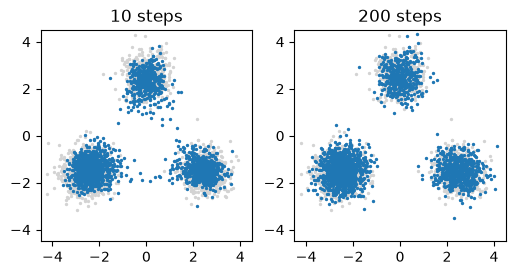

In [5]:
samples = {n: d2l.ddim_sample(pred_exact, z, vp, n)
           for n in (5, 10, 20, 50, 200, 1000)}
spread = lambda pts: f'{mix.summary(pts)["spread"]:.3f}'
for n, x in samples.items():
    gap = (x - samples[1000]).norm(dim=1).mean()
    eta1 = d2l.ddim_sample(pred_exact, z, vp, n, eta=1.0)
    chain = d2l.ancestral_sample(pred_exact, z, vp, n)
    print(f'{n:4d} steps: distance to 1,000 steps {gap:.3f}, spread '
          f'{spread(x)} (eta = 1: {spread(eta1)}, ancestral: {spread(chain)})')
d2l.scatter_panels([samples[10][:2000], samples[200][:2000]],
                   ['10 steps', '200 steps'], data=data[:2000]);

<!-- d2l:prose id=samplers-md-5 fw=all -->

The distance halves each time the number of steps doubles, as predicted:
about 0.4 at five steps, 0.2 at ten and 0.04 at fifty, on a scale where the
modes are about five units apart. The error also has a direction. With ten
steps the spread of the deterministic samples is about 0.38 against the
data's 0.47 to 0.48, and the clouds in the left panel are visibly tighter
than the data behind them. A stride holds the noise estimate at its value at
the start, which for Gaussian data always removes too much noise (Exercise
2), and once the noise is small enough to
tell the modes apart, each mode of the mixture behaves like Gaussian data
with variance $0.25$ per coordinate.

The stochastic samplers miss in both directions. With ten steps $\eta = 1$
contracts the modes further, to a spread of about 0.32, and the ancestral
chain spreads them to about 0.52, beyond the data. It is surprising at first
that $\eta = 1$, which adds noise, ends tighter than $\eta = 0$, which adds
none. Every member splits the same budget $\sigma_s^2$ between kept noise
and fresh noise. For Gaussian data the clean estimate and the noise
estimate are both positive multiples of $\mathbf{x}_t$, so the kept noise
lines up with the clean estimate and adds to its spread through a cross
term. Fresh noise is independent of both and adds its variance and nothing
more. Moving the budget from kept to fresh noise, as $\eta = 1$ does on a
coarse grid, therefore narrows the sample (Exercise
2 proves it). The ancestral chain keeps as
much noise as $\eta = 1$ but adds fresh noise beyond the budget, and the
excess suits data as wide as the noise, not a mode narrower than the noise.
On fine grids all three samplers reach the data's spread. A statistic that
can err in either direction cannot rank samplers by its size, so on images
we use a score that penalizes error in either direction.

### Second Order and the Step Grid

Euler's method holds the slope fixed across a step, so its error over the
whole run falls only in proportion to the step size. Heun's method
(that section) takes the Euler step as a trial,
evaluates the slope again at the trial point, and moves with the average of
the two slopes:

$$
\begin{aligned}
\bar{\mathbf{x}}' &= \bar{\mathbf{x}}_t + (\bar\sigma_s - \bar\sigma_t)\, \hat{\boldsymbol\epsilon}(\bar{\mathbf{x}}_t, \bar\sigma_t), \\
\bar{\mathbf{x}}_s &= \bar{\mathbf{x}}_t + (\bar\sigma_s - \bar\sigma_t)\, \frac{\hat{\boldsymbol\epsilon}(\bar{\mathbf{x}}_t, \bar\sigma_t) + \hat{\boldsymbol\epsilon}(\bar{\mathbf{x}}', \bar\sigma_s)}{2}.
\end{aligned}
$$

Its error falls with the square of the step size, at two evaluations per
step. For standard Gaussian data the noise estimate is
$\hat{\boldsymbol\epsilon} = \bar\sigma \bar{\mathbf{x}} / (1 +
\bar\sigma^2)$, and the exact flow multiplies $\bar{\mathbf{x}}$ by
$\sqrt{(1 + \bar\sigma_s^2) / (1 + \bar\sigma_t^2)}$. From $\bar\sigma_t =
1$ to $\bar\sigma_s = 0.5$ the exact factor is $0.791$, Euler's step gives
$0.75$ and Heun's $0.80$: errors of $0.041$ and $0.009$, about a quarter of
the error for twice the evaluations. Two steps cannot take a second slope.
At $\bar\sigma = 0$ there is no noise left to estimate, and a step from
$\bar\sigma = \infty$ is infinitely long and can be written only in the
form $\hat{\mathbf{x}}_0 + \bar\sigma_s \hat{\boldsymbol\epsilon}$. The
last step, to $\bar\sigma = 0$, and a first step from $\bar\sigma = \infty$
are therefore Euler steps, and `heun_sample` spends $2n - 1$ evaluations
on $n$ steps, or $2n - 2$ from pure noise on the linear path.

Whether the second evaluation helps depends on where the steps are. On a
one-dimensional mixture with the exact field, Heun's method on an even grid
loses to Euler's below about forty evaluations, while on a grid crowded
toward the data it wins at every budget, and the same crowding more than
doubles the error of Euler's method
(that section).
@Karras.Aittala.Aila.ea.2022 separated two choices that earlier
samplers had made together, the order of the method and the placement of its
steps, and crowd the steps by spacing $\bar\sigma^{1/\rho}$ evenly,

$$\bar\sigma_i = \Big(\bar\sigma_{\max}^{1/\rho} + \tfrac{i}{n - 1}\big(\bar\sigma_{\min}^{1/\rho} - \bar\sigma_{\max}^{1/\rho}\big)\Big)^{\rho}, \qquad i = 0, \ldots, n - 1,$$

followed by a last step to $\bar\sigma = 0$, with $\bar\sigma_{\max} = 80$,
$\bar\sigma_{\min} = 0.002$ and $\rho = 7$ for images in $[-1, 1]$. The grid
is a choice of the sampler, separate from the training path, since
`make_pred` translates any level to the network's own time. `edm_grid`
returns these levels and `heun_sample` takes Heun steps through any list of
levels. We print the ten-step grid of each of three choices: even in time
on the variance-preserving path, even in time on the linear path, and the
grid of Karras et al., which we call the EDM grid after their paper,
*Elucidating the Design Space of Diffusion-Based Generative Models*.

In [6]:
def edm_grid(steps, sigma_max=80.0, sigma_min=0.002, rho=7):
    """Karras et al.'s levels sigma_bar: even in sigma_bar^(1/rho), then 0."""
    hi, lo = sigma_max ** (1 / rho), sigma_min ** (1 / rho)
    return [(hi + i / (steps - 1) * (lo - hi)) ** rho
            for i in range(steps)] + [0.0]

@torch.no_grad()
def heun_sample(pred, x, sigma_bars):
    """Heun on d x_bar / d sigma_bar = eps: an Euler trial, then the average
    of the two slopes; from x at the first level to data, as ode_sample."""
    r0 = sigma_bars[0]
    xb = x if math.isinf(r0) else x * math.sqrt(1 + r0 ** 2)  # x / alpha
    for r_t, r_s in zip(sigma_bars[:-1], sigma_bars[1:]):
        x0, eps = d2l.pred_bar(pred, xb, r_t)
        x_next = x0 + r_s * eps                       # the Euler step
        if r_s > 0 and not math.isinf(r_t):           # no slope at 0 or inf
            x_next = xb + (r_s - r_t) * (
                eps + d2l.pred_bar(pred, x_next, r_s)[1]) / 2
        xb = x_next
    return xb

for name, levels in (('VP', vp.sigma_bars(10)), ('linear', lin.sigma_bars(10)),
                     ('EDM', d2l.edm_grid(10))):
    print(f'{name:7s}', ' '.join(f'{r:7.3g}' for r in levels))

VP          152    58.8    25.1    11.8     6.1    3.41    2.03    1.23    0.72    0.34       0
linear      inf       9       4    2.33     1.5       1   0.667   0.429    0.25   0.111       0
EDM          80    42.4    21.1    9.72    4.07     1.5    0.47   0.117  0.0204   0.002       0


<!-- d2l:prose id=samplers-md-6 fw=all -->

Grids that are even in time look nothing alike in $\bar\sigma$. The
variance-preserving grid spends four of its ten steps between $152$ and
$6.1$ and reaches the data from $0.34$. The linear grid covers everything
above $9$ in a single step from infinity and spends seven steps between $4$
and $0.11$. The EDM grid starts at $80$, also spends four steps above $4$,
and crowds its last three levels below $0.12$. Which allocation suits a
model cannot be read off the levels; we measure it on images below.

### Exponential Integrators and Multistep Solvers

Heun's method needs a second evaluation per step for its second order. A
cheaper route starts from the coordinates we have been using, and it turns
out that we have been on it all along. In $\mathbf{x}$, the probability-flow
ODE has a part that is linear in $\mathbf{x}$ and owes nothing to the
network: on the variance-preserving path, for instance, the drift shrinks
$\mathbf{x}$ at the rate $\tfrac12\beta(t)$ whatever the score is, where
$\beta(t)$ is the rate of the noise schedule. The exact solution of this
linear part is an exponential decay, here the factor $\alpha_t$, and
dividing by $\alpha_t$ removes it. What remains, $d\bar{\mathbf{x}} /
d\bar\sigma = \hat{\boldsymbol\epsilon}$, contains only the network.
Integrating the linear part exactly and approximating only the network's
term is the idea of an *exponential integrator*
[@Zhang.Chen.2023; @Lu.Zhou.Bao.ea.2022]. DDIM, which holds
$\hat{\boldsymbol\epsilon}$ constant over the step, is its first-order
member, so the change of coordinates that made DDIM look like Euler's method
was the main idea of these solvers. The higher-order members differ only in
how they let $\hat{\boldsymbol\epsilon}$ vary across the step. DPM-Solver
[@Lu.Zhou.Bao.ea.2022] evaluates it a second time, at the midpoint of
the step in $\log \bar\sigma$ (Exercise 3).

The second evaluation can be avoided. The previous step has already
evaluated $\hat{\boldsymbol\epsilon}$ at the level we just left, and a
*multistep* method reuses it: it extrapolates $\hat{\boldsymbol\epsilon}$
linearly from the last two estimates to the middle of the current step. With
$\Delta = \bar\sigma_s - \bar\sigma_t$ for the current step, $\Delta'$ for
the previous one, and $\hat{\boldsymbol\epsilon}_t$,
$\hat{\boldsymbol\epsilon}'$ the estimates at their starts, the
second-order Adams--Bashforth step is

$$\bar{\mathbf{x}}_s = \bar{\mathbf{x}}_t + \Delta \Big(\hat{\boldsymbol\epsilon}_t + \frac{\Delta}{2\Delta'}\big(\hat{\boldsymbol\epsilon}_t - \hat{\boldsymbol\epsilon}'\big)\Big).$$

When the noise estimate does not change from one step to the next, this is
DDIM; otherwise the correction follows the change, at one evaluation per
step. The first step has no previous estimate and is an Euler step, and so
is the step after a start at $\bar\sigma = \infty$, where $\Delta'$ is
infinite. DPM-Solver++(2M) [@Lu.Zhou.Bao.ea.2025] applies the same idea
to the clean-image estimate and extrapolates in $\log \bar\sigma$; it and
its relatives are the usual choice at ten to twenty-five evaluations.
`multistep_sample` takes the step above through any list of levels.

In [7]:
@torch.no_grad()
def multistep_sample(pred, x, sigma_bars):
    """Second-order Adams-Bashforth on d x_bar / d sigma_bar = eps: one
    evaluation per step, the slope extrapolated from the last two."""
    r = sigma_bars
    xb = x if math.isinf(r[0]) else x * math.sqrt(1 + r[0] ** 2)  # x / alpha
    eps_prev = 0
    for k in range(len(r) - 1):
        x0, eps = d2l.pred_bar(pred, xb, r[k])
        c = ((r[k + 1] - r[k]) ** 2 / (2 * (r[k] - r[k - 1]))
             if k > 0 and math.isfinite(r[k - 1]) else 0.0)  # 0: Euler
        xb = x0 + r[k + 1] * eps + c * (eps - eps_prev)
        eps_prev = eps
    return xb

<!-- d2l:prose id=samplers-md-7 fw=all -->

### Quality against Evaluations on Images

On images the field is learned. We train the class-conditional U-Net of
that section (about 1.2 million parameters) on the
velocity of the linear path for ten thousand updates, a few minutes on one
GPU. A tenth of its labels are replaced by a null label, and we sample from
the moving average of its weights. This one network serves the rest of the
section. Samplers without guidance ($\gamma = 1$ below) ask for every class
equally often (sample $i$ for class $i$ mod 10), guided ones ($\gamma > 1$)
also evaluate the null label, and inversion and editing give each image its
own label.

In [8]:
X, y, X_test, y_test = d2l.load_fashion_mnist_pm1()
loss = d2l.regression_loss(lin, 'velocity')

def batch_fn():
    i = torch.randint(0, len(X), (128,), device=X.device)
    drop = torch.rand(128, device=X.device) < 0.1   # label dropout
    return X[i], torch.where(drop, 10, y[i])        # 10 is the null label

def loss_fn(net, batch):  # the regression loss of the labeled field
    x0, c = batch
    return loss(d2l.conditional(net, c), x0)

torch.manual_seed(0)
net = d2l.UNet(ch=64, num_classes=10).to(X.device)
net, ema, _ = d2l.train_regression(net, loss_fn, batch_fn, 10_000)

<!-- d2l:prose id=samplers-md-8 fw=all -->

We score 1,000 samples by their Fréchet distance (FD) to 1,000 test images
in `d2l.FeatureCNN` features (that section). At this size
two sets of real images already score a little under 1 against each other,
and the score moves by 0.15 to 0.2 from one draw of images to the next
(that section). Every measurement is therefore
repeated on three draws of 1,000 noise images, shared by all samplers so
that every comparison is paired, and reported as the mean plus or minus half
the range; the floor compares the test images with three other real sets. A
difference within the half-ranges is not a difference. `fd_runs` also takes
a guidance scale $\gamma$, which we use in the next subsection; $\gamma = 1$
is the plain conditional field.

In [9]:
cnn = d2l.fashion_feature_cnn(X, y)
features = lambda imgs: d2l.fd_features(cnn, imgs)
f_test = features(X_test[:1000])
floors = [d2l.fid_score(features(X_test[k:k + 1000]), f_test)
          for k in (1000, 2000, 3000)]
labels = torch.arange(1000, device=X.device) % 10   # sample i has class i % 10
gen = torch.Generator(X.device).manual_seed(1)
noises = [torch.randn(1000, 1, 28, 28, device=X.device, generator=gen)
          for _ in range(3)]                        # shared by every sampler

def fd_runs(sampler, n, gamma=1.0):
    """FD of sampler(pred, noise, n) on each noise draw, field cfg(gamma)."""
    pred = d2l.make_pred(d2l.cfg(ema, labels, gamma), lin, 'velocity')
    return [d2l.fid_score(features(sampler(pred, z, n).clamp(-1, 1)), f_test)
            for z in noises]

def mean_range(fds):  # the mean, plus or minus half the range of the draws
    return f'{np.mean(fds):5.2f}±{(max(fds) - min(fds)) / 2:.2f}'

print('floor, 1,000 real images against 1,000 others: FD', mean_range(floors))

floor, 1,000 real images against 1,000 others: FD  0.86±0.15


<!-- d2l:prose id=samplers-md-9 fw=all -->

The floor is about 0.9. The first table settles the question left open
above, on the variance-preserving path with even steps in time, so that DDIM
with $\eta = 0$ is Euler's method on the first grid printed above. If noise
corrects errors that a deterministic sampler carries to the end, $\eta = 1$
and the ancestral chain should close on $\eta = 0$ as the steps shorten and
overtake it before a thousand.

In [10]:
vp_samplers = {  # the DDIM family and the ancestral chain, even steps on VP
    'DDIM, eta = 0': lambda p, z, n: d2l.ddim_sample(p, z, vp, n),
    'DDIM, eta = 1': lambda p, z, n: d2l.ddim_sample(p, z, vp, n, eta=1.0),
    'ancestral': lambda p, z, n: d2l.ancestral_sample(p, z, vp, n)}
steps = (10, 20, 50, 100, 200, 1000)
torch.manual_seed(2)  # the fresh noise of the stochastic samplers
fd_vp = {name: [fd_runs(f, n) for n in steps]
         for name, f in vp_samplers.items()}
print('steps        ', ''.join(f'{n:>11d}' for n in steps))
for name, row in fd_vp.items():
    print(f'{name:13s}', ''.join(f'{mean_range(v):>11s}' for v in row))

steps                  10         20         50        100        200       1000
DDIM, eta = 0   5.41±0.32  2.95±0.19  1.76±0.12  1.45±0.11  1.33±0.10  1.32±0.10
DDIM, eta = 1   7.81±0.23  4.90±0.16  3.06±0.09  2.32±0.06  1.98±0.08  1.52±0.05
ancestral      28.66±0.26 19.22±0.63  7.85±0.10  3.45±0.14  1.78±0.13  1.34±0.03


<!-- d2l:prose id=samplers-md-10 fw=all -->

They close on it but never overtake it. Up to two hundred steps $\eta = 0$
scores between a third and nearly a half lower than $\eta = 1$ at every
budget, far outside the half-ranges; at a thousand the three end within
about 0.2 of each other, between about 1.3 and 1.5. On this model fresh
noise never helped: at no budget did a stochastic sampler beat $\eta = 0$
by more than the half-ranges, and at a thousand steps the ancestral chain
only ties it. Up to a hundred steps the ancestral chain loses most, with
about 8 to 11 at fifty steps, worse than DDIM at ten (a little over 5). Its
forward-step variance suits data as wide as the noise, but a garment is
nearly determined once the noise is small, and the excess variance should
show as speckle; the image rows at the end of the next subsection show it.
DDIM itself changes by about a tenth after a hundred steps, and at fifty it
is within about a third of the thousand-step chain at a twentieth of the
evaluations, which is the central result of @Song.Meng.Ermon.2020 .

The verdict on fresh noise belongs to this model, and it should not be
carried over to large ones. On ImageNet at $64 \times 64$ pixels
@Karras.Aittala.Aila.ea.2022 found that a small, tuned amount of
noise added before each Heun step improved on their deterministic sampler,
the predictor-corrector samplers of @song2021score insert Langevin
steps between solver steps to the same effect, and Restart sampling
[@Xu.Deng.Cheng.ea.2023] gains most at large budgets. The mechanism is
the Langevin pull described above. A large model of hard data makes errors
that later noise can still correct, and given enough steps the correction
outweighs the variance that the noise adds.

The second table counts network evaluations rather than steps, since that is
what a sample costs. It runs Euler's method, Heun's method and the multistep
sampler at about 10 to 100 evaluations on three grids: the linear grid, the
EDM grid of Karras et al. with $\rho = 7$, and the same with $\rho = 3$,
which moves levels from the data end toward high noise. Heun's method takes
about half as many steps, and on the EDM grids, which start at a finite
level, one evaluation fewer than the budget.

In [11]:
grids = {'linear': lin.sigma_bars, 'EDM': d2l.edm_grid,
         'EDM, rho = 3': lambda n: d2l.edm_grid(n, rho=3)}
solvers = {'Euler': d2l.ode_sample, 'Heun': d2l.heun_sample,
           'multistep': multistep_sample}
budgets = (10, 20, 50, 100)  # network evaluations per sample

def on_grid(solver, grid):  # a sampler (pred, noise, steps)
    return lambda p, z, n: solver(p, z, grid(n))

def num_steps(s, g, b):  # Heun skips its second slope only at sigma = inf, 0:
    # b // 2 + 1 steps on the linear grid (b evaluations, the first level is
    # infinite), b // 2 on the EDM grids (b - 1)
    return (b // 2 + (g == 'linear')) if s == 'Heun' else b

fd_ode = {(s, g): [fd_runs(on_grid(solver, grid), num_steps(s, g, b))
                   for b in budgets]
          for s, solver in solvers.items() for g, grid in grids.items()}
print('evaluations            ', ''.join(f'{b:>11d}' for b in budgets))
for (s, g), row in fd_ode.items():
    print(f'{s + ", " + g:23s}', ''.join(f'{mean_range(v):>11s}' for v in row))

evaluations                      10         20         50        100
Euler, linear             3.33±0.25  1.99±0.15  1.46±0.11  1.36±0.10
Euler, EDM                6.81±0.38  3.14±0.22  1.86±0.15  1.58±0.14
Euler, EDM, rho = 3       9.74±0.47  4.02±0.25  2.02±0.16  1.62±0.14
Heun, linear              1.60±0.12  1.27±0.07  1.20±0.08  1.25±0.09
Heun, EDM                11.71±0.29  1.69±0.08  1.32±0.10  1.37±0.11
Heun, EDM, rho = 3       84.52±0.45  8.10±0.26  1.47±0.11  1.39±0.11
multistep, linear         2.12±0.17  1.42±0.11  1.29±0.10  1.30±0.10
multistep, EDM            4.50±0.28  1.96±0.16  1.46±0.12  1.41±0.12
multistep, EDM, rho = 3   6.56±0.35  2.37±0.17  1.46±0.12  1.39±0.12


<!-- d2l:prose id=samplers-md-11 fw=all -->

Where do the two tables meet? The plot puts the first table's samplers and
the three solvers on the linear grid on one axis of network evaluations.

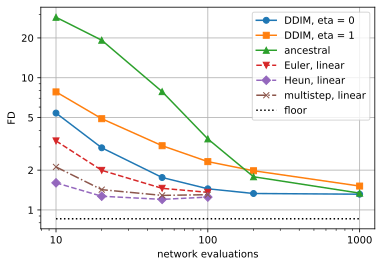

In [12]:
curves = {**{name: (steps, row) for name, row in fd_vp.items()},
          **{f'{s}, linear': (budgets, fd_ode[s, 'linear']) for s in solvers}}
d2l.plot([x for x, _ in curves.values()] + [[10, 1000]],
         [[np.mean(v) for v in row] for _, row in curves.values()]
         + [[np.mean(floors)] * 2], 'network evaluations', 'FD',
         legend=list(curves) + ['floor'], xscale='log', yscale='log',
         figsize=(6, 4), fmts=('o-', 's-', '^-', 'v--', 'D--', 'x-.', 'k:'))

<!-- d2l:prose id=samplers-md-12 fw=all -->

The second-order methods reach the model's asymptotic FD plateau ($\approx 1.1$–$1.3$, about $0.3$ above the finite-sample floor) first: Heun's method on the linear grid reaches $\approx 1.2$–$1.3$ at 20 function evaluations, the second-order multistep solver reaches it by 50, and Euler's method requires 50 to 100.

Step placement matters as much as solver order. At 10 evaluations, Euler's method scores $\approx 3.2$ on the linear grid, $\approx 5$ on the VP grid, and $\approx 6.5$ on the EDM ($\rho = 7$) grid, while Heun's method scores $\approx 1.6$ on the linear grid versus $12$–$15$ on EDM. Lowering $\rho$ to $3$ (which shifts steps from the data end toward high noise) degrades 10- and 20-evaluation performance even further. Above $\bar\sigma \approx 4$ (several times the pixel standard deviation $\approx 0.7$), the noisy image is nearly pure Gaussian noise and trajectories are almost straight; the linear grid crosses $\bar\sigma > 4$ in two steps ($\infty \to 9 \to 4$), whereas the 10-step EDM grid spends four steps there and leaves too few steps for the intermediate regime where garment structure forms.

### Integration Error, Guidance and the Choice of a Sampler

So far FD alone has judged the samplers, and FD scores a set of samples. It
does not say how far each sample lies from the point that an exact
integration of the field would reach from the same noise image. To see what
a solver loses beyond what FD notices, we integrate every noise image with
200 evaluations of Heun's method as a reference and measure each solver's
root-mean-square distance per pixel to it.

We do this for two fields, since guidance changes the field being
integrated. Classifier-free guidance
(that section) extrapolates from the unlabeled
to the labeled prediction, $\tilde{\mathbf{u}} = \mathbf{u}_\varnothing +
\gamma(\mathbf{u}_c - \mathbf{u}_\varnothing)$, so $\gamma = 1$ is the
conditional field and each guided evaluation costs two network passes. A
field that extrapolates beyond both of its parts should also change faster
along a trajectory, and we expect every solver to need more evaluations to
follow it at $\gamma = 2$.

In [13]:
def endpoints(solver, n, gamma):
    """Samples of a solver with n steps on the linear grid, per noise draw."""
    pred = d2l.make_pred(d2l.cfg(ema, labels, gamma), lin, 'velocity')
    return [solver(pred, z, lin.sigma_bars(n)).clamp(-1, 1) for z in noises]

for gamma in (1.0, 2.0):
    refs = endpoints(d2l.heun_sample, 101, gamma)    # 200 evaluations
    fds = [d2l.fid_score(features(x), f_test) for x in refs]
    print(f'gamma = {gamma:.0f}, reference: FD {mean_range(fds)}; '
          'FD and RMS distance to it')
    print('evaluations', ''.join(f'{b:>18d}' for b in (10, 20, 50)))
    for s, solver in solvers.items():
        cols = []
        for b in (10, 20, 50):
            xs = endpoints(solver, b // 2 + 1 if s == 'Heun' else b, gamma)
            fds = [d2l.fid_score(features(x), f_test) for x in xs]
            rms = np.mean([((x - r) ** 2).mean().sqrt().item()
                           for x, r in zip(xs, refs)])
            cols.append(f'  {mean_range(fds)} {rms:.3f}')
        print(f'  {s:9s}', ''.join(cols))

gamma = 1, reference: FD  1.29±0.09; FD and RMS distance to it
evaluations                 10                20                50


  Euler        3.33±0.25 0.108   1.99±0.15 0.063   1.46±0.11 0.030


  Heun         1.60±0.12 0.127   1.27±0.07 0.044   1.20±0.08 0.014


  multistep    2.12±0.17 0.094   1.42±0.11 0.044   1.29±0.10 0.015


gamma = 2, reference: FD  2.29±0.11; FD and RMS distance to it
evaluations                 10                20                50


  Euler        3.88±0.14 0.109   3.07±0.11 0.066   2.57±0.10 0.035


  Heun         3.51±0.15 0.142   2.77±0.10 0.066   2.43±0.10 0.021


  multistep    3.31±0.12 0.099   2.71±0.10 0.051   2.38±0.10 0.021


<!-- d2l:prose id=samplers-md-13 fw=all -->

The two measures disagree, and the disagreement teaches something about FD.
At ten evaluations without guidance, Heun's samples lie farther from the
reference than Euler's (a distance of 0.12 to 0.13 against about 0.1), yet
their FD is half of Euler's (about 1.6 against about 3.2). FD scores the
distribution of the samples, not the error of each one: a solver can draw
the wrong garment for a given noise image and still draw a realistic set.

Guidance makes the field harder to follow, as expected. At $\gamma = 2$ the
reference itself scores about 2.1 to 2.3, since guidance trades realism for
agreement with the class. At twenty evaluations every solver is still 0.4
to 1 above it; by fifty the multistep sampler has reached the reference's
range or its edge, while Heun's method is 0.15 to 0.2 above it and Euler's
about 0.3. The distances confirm the prediction only in part. At twenty
evaluations Heun's distance to the reference is a third to a half larger
than without guidance, but Euler's and the multistep sampler's have moved
by a sixth or less, and at ten and twenty evaluations the multistep sampler
is the closest of the three. Under guidance, then, only the multistep sampler
reaches the plateau by fifty evaluations, a hundred network passes; Heun's
and Euler's methods need more, and the table does not say how many.

The integration error can also be seen. Below are eight images from each of
four samplers, from the same eight noise images and labels: the ancestral
chain with 50 steps, DDIM with 10 and with 50 steps, and Heun's method on
the linear grid with 20 evaluations.

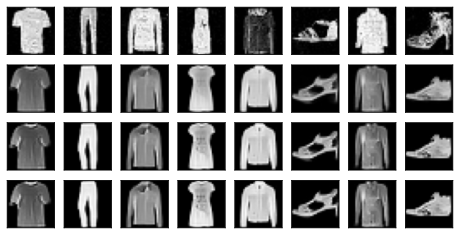

In [14]:
z8 = noises[0][:8]
pred8 = d2l.make_pred(d2l.conditional(ema, labels[:8]), lin, 'velocity')
rows = [d2l.ancestral_sample(pred8, z8, vp, 50),
        d2l.ddim_sample(pred8, z8, vp, 10), d2l.ddim_sample(pred8, z8, vp, 50),
        d2l.heun_sample(pred8, z8, lin.sigma_bars(11))]
d2l.show_gray(torch.cat(rows).clamp(-1, 1), 4, 8);

<!-- d2l:prose id=samplers-md-14 fw=all -->

The three deterministic rows match column by column, since the
deterministic samplers approximate one map from noise to images; ten steps
smooth away details, such as prints and edges, that fifty steps and Heun's
method agree on. The ancestral row is grainy, with speckled backgrounds and
textures. This is the excess variance of the first table, made visible.

How, then, should we choose a sampler for a model we have not measured? Fix
a set of noise images and a score, start with a deterministic solver on the
grid of the model's own training path, and double the number of evaluations
until the score stops moving by more than its run-to-run range. What remains
is the model's error; the best a sampler can do is stop adding its own. On
this model the procedure stops where the curves of the plot level off,
about twenty evaluations for Heun's method, and fresh noise never helps.
Under guidance it stops later, at about fifty evaluations of the multistep
sampler, which with one evaluation per step and the smallest integration
error is the better default there. A grid taken from a paper should pass the
same test before it replaces the training grid. At ten evaluations no solver
has reached the plateau, and reaching it in one or two steps needs a
different kind of model (that section).

## Inversion and Editing

A deterministic sampler integrates a differential equation, and a
differential equation can be run in either direction. Running it backwards
gives each image a noise image, its *code*, from which the sampler
reproduces the image. Codes allow interpolation between images. The same
sampler, started from a partly noised image or constrained at every step,
edits and inpaints, all without retraining.

### The Latent Code

`ddim_invert` runs the deterministic sampler upward, from an image at
$t = 0$ toward noise. Each step goes from a level $t$ to the next level
$t' > t$ by the Euler step

$$\bar{\mathbf{x}}_{t'} = \bar{\mathbf{x}}_t + (\bar\sigma_{t'} - \bar\sigma_t)\, \hat{\boldsymbol\epsilon}(\bar{\mathbf{x}}_t, \bar\sigma_t),$$

with the noise estimate read at the lower end, the only point the encoder
has. The first step, at $\bar\sigma = 0$ where the predictor is undefined,
reads the image with the noise level of the next level instead.

In [15]:
@torch.no_grad()
def ddim_invert(pred, x, path, steps, t_end=1.0):
    """Deterministic DDIM run backwards, from data x at t = 0 to t_end."""
    a, s = path.grid(steps, 0.0, t_end)
    for i in range(steps):
        j = max(i, 1)  # at t = 0 (sigma = 0) x is read at the next level
        eps = pred(x, a[j], s[j])[1]
        x = a[i + 1] * (x - s[i] * eps) / a[i] + s[i + 1] * eps
    return x

<!-- d2l:prose id=samplers-md-15 fw=all -->

The decoder steps back down with
$\hat{\boldsymbol\epsilon}(\bar{\mathbf{x}}_{t'}, \bar\sigma_{t'})$, read at
the upper end. The two estimates differ by the change of
$\hat{\boldsymbol\epsilon}$ over a step, so the round trip is inexact even
with an exact field, and its error should shrink with the step size like any
first-order error. The round trip runs one field in both directions, so its
error is the error of the steps on that field, whether or not the field is
right. What the learned field can still do is change faster along its
trajectories than an exact field would; its round trip would then converge
more slowly than one through an exact field. We encode and decode 100 test
images, each with its own label, with 10 to 200 steps on the linear path,
and send the 20,000 mixture points through the same round trip with the
exact field.

 10 steps: squared error per pixel 0.0347, code std 0.69; mixture 0.3097
 20 steps: squared error per pixel 0.0148, code std 0.76; mixture 0.0878


 50 steps: squared error per pixel 0.0039, code std 0.81; mixture 0.0192


100 steps: squared error per pixel 0.0011, code std 0.84; mixture 0.0074


200 steps: squared error per pixel 0.0002, code std 0.86; mixture 0.0023


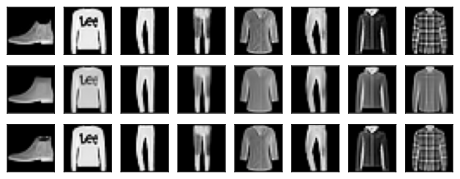

In [16]:
x0 = X_test[:100]
pred = d2l.make_pred(d2l.conditional(ema, y_test[:100]), lin, 'velocity')
codes = {n: d2l.ddim_invert(pred, x0, lin, n) for n in (10, 20, 50, 100, 200)}
recon = {n: d2l.ddim_sample(pred, code, lin, n) for n, code in codes.items()}
for n in codes:  # the mixture's points through its exact field, for contrast
    back = d2l.ddim_sample(pred_exact, d2l.ddim_invert(pred_exact, data, lin, n),
                           lin, n)
    print(f'{n:3d} steps: squared error per pixel '
          f'{((recon[n] - x0) ** 2).mean():.4f}, code std {codes[n].std():.2f}; '
          f'mixture {((back - data) ** 2).mean():.4f}')
d2l.show_gray(torch.cat([x0[:8], recon[10][:8], recon[50][:8]]), 3, 8);

<!-- d2l:prose id=samplers-md-16 fw=all -->

Both round trips are inexact, and both errors fall steadily: from ten to a
hundred steps the root-mean-square error shrinks about sixfold in both, well
short of the tenfold of a first-order error, and from fifty steps on the
images' error falls at least as fast as the mixture's. The learned field is
therefore no rougher along its trajectories than an exact one, and what
remains is the error of the steps. At fifty steps it is 0.05 to 0.06 per
pixel on a scale from $-1$ to $1$, and the third row is close to the
originals; at ten steps it is about 0.19, and the second row loses detail
such as the check pattern of the last shirt.

The codes are less satisfactory. Their standard deviation is about 0.7 at
ten steps and still below 0.9 at two hundred, so a code that reproduces its
image is narrower than the noise the sampler was built to start from. A
code is therefore not a typical draw of standard Gaussian noise, and we
have to take care whenever we interpolate between codes or draw new ones
near them.

Methods that edit real photographs through their codes meet a second,
separate difficulty. Inversion follows the trajectory of one field, and a
guided sampler integrates a different one, so guided sampling from the code
leaves that trajectory and no longer returns the image. Null-text inversion
[@Mokady.Hertz.Aberman.ea.2023] repairs this by optimizing the
null-label embedding at every step until the guided sampler reproduces the
image from its code.

Because the sampler is a continuous function of its code, we can move
between two images by interpolating between their codes. A straight line is
a poor path. Halfway between two codes of equal norm $r$ at an angle
$\omega$ the norm is $r \cos(\omega/2)$, smaller by a factor of about
$\sqrt{2}$ when the codes are nearly orthogonal, as independent noise images
are, and the decoder has never been started from so short a code. Spherical
interpolation moves along the great circle between the two codes instead,

$$
\begin{aligned}
\mathbf{z}_u &= \frac{\sin\big((1 - u)\omega\big)\, \mathbf{z}_0 + \sin(u \omega)\, \mathbf{z}_1}{\sin \omega}, \\
\cos \omega &= \frac{\mathbf{z}_0^\top \mathbf{z}_1}{\|\mathbf{z}_0\| \|\mathbf{z}_1\|},
\end{aligned}
$$

which keeps the norm of the endpoints. We decode eight points between the
50-step codes of two ankle boots among the test images; one class for the
whole row lets the decoder use one label.

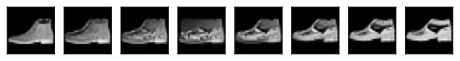

In [17]:
i, j = torch.nonzero(y_test[:100] == y_test[0])[:2, 0]  # one class: one field
z0, z1 = codes[50][i], codes[50][j]
omega = torch.arccos(((z0 * z1).sum() / (z0.norm() * z1.norm())).clamp(-1, 1))
u = torch.linspace(0, 1, 8, device=z0.device).reshape(-1, 1, 1, 1)
zs = (torch.sin((1 - u) * omega) * z0 + torch.sin(u * omega) * z1
      ) / torch.sin(omega)
pred_i = d2l.make_pred(d2l.conditional(ema, y_test[i].repeat(8)), lin,
                       'velocity')
d2l.show_gray(d2l.ddim_sample(pred_i, zs, lin, 50), 1, 8);

<!-- d2l:prose id=samplers-md-17 fw=all -->

The shape changes gradually from one boot to the other, but the middle
frames look more like an overlay of the two boots than like a third one.
Spherical interpolation keeps the codes at the right norm; nothing makes the
decoder map the codes between two boots to a third boot.

### Editing by Partial Noising

Inversion finds the noise that reproduces an image exactly. For editing we
want the opposite: a starting point that forgets the details of the input
and keeps its layout. @Meng.He.Song.ea.2022 therefore noise a rough
input $\mathbf{y}$, such as a sketch or a crude collage, directly with fresh
noise, to an intermediate time $t_0$ with $\mathbf{x}_{t_0} = \alpha_{t_0}
\mathbf{y} + \sigma_{t_0} \boldsymbol\epsilon$, and run the sampler from
$t_0$ back to the data. The noise hides the details of the input that real
images do not have, the sampler replaces them by details that real images
do have, and the coarse layout survives. The time $t_0$ sets the balance
between fidelity to the input and realism. How good can that balance be?

Our rough inputs are the ten class-mean images, blurred silhouettes that no
real garment looks like, each noised a hundred times to $t_0 \in \{0.3,
0.5, 0.7, 1\}$ and integrated back with 25 DDIM steps under its class label.
We print the squared distance per pixel to the input (fidelity) and the FD
of the 1,000 outputs (realism); the row $t_0 = 0$ holds the inputs.

t0 = 0.0: squared distance to the input 0.000, FD 87.04
t0 = 0.3: squared distance to the input 0.018, FD 30.71
t0 = 0.5: squared distance to the input 0.045, FD 12.19
t0 = 0.7: squared distance to the input 0.087, FD 4.01
t0 = 1.0: squared distance to the input 0.168, FD 1.88


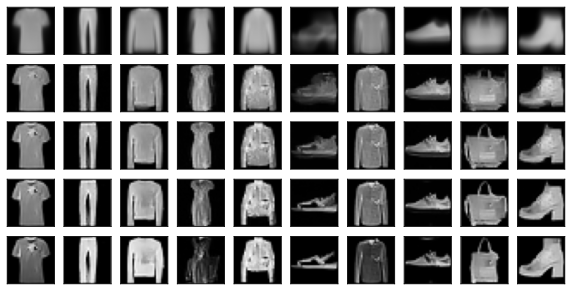

In [18]:
means = torch.stack([X[y == c].mean(0) for c in range(10)])
inputs = means.repeat(100, 1, 1, 1)                  # 1,000 inputs, class i % 10
pred = d2l.make_pred(d2l.conditional(ema, labels), lin, 'velocity')
torch.manual_seed(2)
eps = torch.randn_like(inputs)
edits = {0.0: inputs}
for t0 in (0.3, 0.5, 0.7, 1.0):
    x_t0 = lin.sample(inputs, torch.full((1000,), t0, device=X.device), eps)
    edits[t0] = d2l.ddim_sample(pred, x_t0, lin, 25, t_start=t0).clamp(-1, 1)
for t0, x in edits.items():
    print(f't0 = {t0:.1f}: squared distance to the input '
          f'{((x - inputs) ** 2).mean():.3f}, '
          f'FD {d2l.fid_score(features(x), f_test):.2f}')
d2l.show_gray(torch.cat([x[:10] for x in edits.values()]), 5, 10);

<!-- d2l:prose id=samplers-md-18 fw=all -->

The inputs score an FD of 85 to 87; as $t_0$ grows, the distance to the
input grows and the FD falls. At $t_0 = 0.3$ the outputs are sharper than
the mean images but blotchy, and their FD of about 30 is that of the
ten-step ancestral chain, far from any deterministic sampler's. At $0.5$
they look like garments with odd textures (11 to 12). Only at $0.7$ does
the FD, about 4, come near that of the ten-step deterministic samplers, and
by then the outline and pose are all that survive of the input. At $t_0 = 1$
the input is gone: each output is a fresh sample of its class, with an FD
below 2, and since the two rows start from the same noise images, the rows
at $0.7$ and $1$ often look alike. For an input as crude as a class mean,
realism arrives only at a $t_0$ that leaves little of the input.

### Inpainting

Suppose that we know part of an image, the upper half, say, and want the
model to fill in the rest. Write $\mathbf{m}$ for the mask that is one on
the known pixels and $\mathbf{y}$ for their values. At every level we know
what the known pixels of $\mathbf{x}_s$ should look like: $\alpha_s
\mathbf{y}$ plus noise of scale $\sigma_s$. Replacement inpainting
[@song2021score; @Lugmayr.Danelljan.Romero.ea.2022] therefore takes each
sampler step as usual and then overwrites the known pixels with a fresh
noisy copy of $\mathbf{y}$ at the new level,

$$\mathbf{x}_s \leftarrow \mathbf{m} \odot \big(\alpha_s \mathbf{y} + \sigma_s \boldsymbol\xi\big) + (\mathbf{1} - \mathbf{m}) \odot \mathbf{x}_s.$$

Replacement is an approximation. Each step moves all pixels as if the known
ones were free, then overwrites the known ones with noise that knows nothing
of where the step took them. The unknown pixels learn about the known ones
only through the network's next look at the noisy image, so the sampler
does not draw them exactly from their distribution given the known pixels.
`inpaint` runs the sampler one step at a time to make room for the
overwrite.

In [19]:
@torch.no_grad()
def inpaint(pred, known, mask, path, steps):
    """DDIM from noise that resets the known pixels (mask 1) at each level."""
    a, s = path.grid(steps)
    x = torch.randn_like(known)
    for i in range(steps):
        x0, eps = pred(x, a[i], s[i])
        x = a[i + 1] * x0 + s[i + 1] * eps            # one DDIM step, eta = 0
        noised = a[i + 1] * known + s[i + 1] * torch.randn_like(x)
        x = mask * noised + (1 - mask) * x            # keep the known pixels
    return x

<!-- d2l:prose id=samplers-md-19 fw=all -->

We keep the upper half of eight test images and ask for three completions of
each, from different noise, under each image's label. The rows show the
known halves, the three completions and the originals.

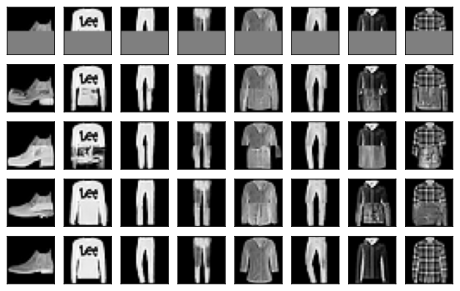

In [20]:
mask = torch.zeros(1, 1, 28, 28, device=X.device)
mask[..., :14, :] = 1                                # the upper half is known
pred = d2l.make_pred(d2l.conditional(ema, y_test[:8].repeat(3)), lin,
                     'velocity')
torch.manual_seed(3)
fills = inpaint(pred, X_test[:8].repeat(3, 1, 1, 1), mask, lin, 50)
d2l.show_gray(torch.cat([X_test[:8] * mask, fills, X_test[:8]]), 5, 8);

<!-- d2l:prose id=samplers-md-20 fw=all -->

Most completions continue the known half into a plausible garment of its
class, and the three completions of one image differ. The approximation
shows at the seam: in several completions, the shirts most clearly, the
lower half takes a different texture or shade from the upper half (Exercise
5 measures and repairs this).

Every sampler in this section integrated the same trained field and differed
only in how. The field itself we have taken on trust: it came from an
unweighted squared error on a target we picked. The next section asks why
this loss is the right one, and what the choices of target, path and
weighting change.

## Summary

Because training depends only on the marginal distribution of $\mathbf{x}_t$ at each time $t$, a single trained network supports the entire DDIM sampler family parameterized by the stochasticity strength $\eta \ge 0$. At $\eta = 0$, DDIM is deterministic and coincides with Euler's method on the probability-flow ODE $d\bar{\mathbf{x}}/d\bar\sigma = \hat{\boldsymbol\epsilon}$ in the rescaled coordinates $(\bar{\mathbf{x}}, \bar\sigma) = (\mathbf{x}/\alpha_t, \sigma_t/\alpha_t)$. On our Fashion-MNIST model, deterministic ODE solvers consistently outperform stochastic samplers ($\eta = 1$ and the ancestral chain) at small and moderate budgets: Heun's second-order method on the linear grid reaches the model's FD plateau in about 20 evaluations, while the second-order Adams–Bashforth multistep solver reaches the guided plateau by 50 evaluations at one evaluation per step. Running the deterministic ODE backward (`ddim_invert`) maps any image to a latent noise code, supporting spherical latent interpolation, partial-noising image edits, and replacement inpainting without retraining.

## Exercises

1. **The forward step and the Markov member.** ● Given $\mathbf{x}_0$, draw
   $\mathbf{x}_t = \alpha_t \mathbf{x}_0 + \sigma_t \boldsymbol\epsilon$ and
   $\mathbf{x}_s$ from the equation with the same
   $\boldsymbol\epsilon$.
    1. Compute the mean and the covariance of $\mathbf{x}_t$ given
       $\mathbf{x}_s$ and $\mathbf{x}_0$ by conditioning the joint Gaussian.
    1. Show that the mean depends on $\mathbf{x}_0$ unless $\tilde\sigma$
       takes its value at $\eta = 1$, and that the conditional is then the
       forward step $\mathbf{x}_t = (\alpha_t / \alpha_s) \mathbf{x}_s +
       \sqrt{\sigma_t^2 - (\alpha_t / \alpha_s)^2 \sigma_s^2}\,
       \boldsymbol\nu$ of the noising chain of
       that section, and conclude that this chain
       is the only member of the family whose forward process is Markov.
    1. Show that with $\tilde\sigma = 0$ at every step the forward process
       is $\mathbf{x}_t = \alpha_t \mathbf{x}_0 + \sigma_t
       \boldsymbol\epsilon$ with one $\boldsymbol\epsilon$ shared by all
       times. Why can the regression not tell these forward processes apart?
1. **Gaussian data.** Let the data be one-dimensional with distribution
   $\mathcal{N}(0, v)$.
    1. In the coordinates $(\bar x, \bar\sigma)$, show that the exact noise
       estimate is $\hat\epsilon = \bar\sigma \bar x / (v + \bar\sigma^2)$,
       that one deterministic stride from $\bar\sigma$ to $\bar\sigma'$
       multiplies $\bar x$ by $(v + \bar\sigma \bar\sigma') / (v +
       \bar\sigma^2)$, and that the exact flow multiplies it by $\sqrt{(v +
       \bar\sigma'^2) / (v + \bar\sigma^2)}$.
    1. Show that the factor of the stride never exceeds the exact one, with
       equality only for $\bar\sigma' = \bar\sigma$. What does this imply for
       the variance of deterministic samples of Gaussian data on any grid?
    1. Now take any member of the family the equation
       with $0 \leq \eta \leq 1$ and exact estimates. Write the variance of
       $x_s$ after one step from $x_t \sim \mathcal{N}(0, \alpha_t^2 v +
       \sigma_t^2)$ as a function of $c = \sqrt{\sigma_s^2 -
       \tilde\sigma^2}$, and show with the Cauchy--Schwarz inequality that it
       stays below the exact $\alpha_s^2 v + \sigma_s^2$ and falls as $\eta$
       grows. Which of the spreads printed in this section does this explain?
    1. Take $v = 0.25$, the variance of one coordinate of a mode of `mix`.
       Compute the standard deviation $s$ of deterministic samples from $x_1
       \sim \mathcal{N}(0, 1)$ on the variance-preserving grids with 200,
       50, 20, 10 and 5 steps. Compare $2s^2$, the spread of a
       two-dimensional cloud with this standard deviation per coordinate,
       with the data's $0.5$ and with the spreads printed in this section.
       Does a Gaussian mode predict the mixture's contraction, more of it,
       or less?
1. [extended] **A second-order sampler in log-SNR.** ●● DPM-Solver-2
   [@Lu.Zhou.Bao.ea.2022] takes a step from $\bar\sigma$ to
   $\bar\sigma'$ in two evaluations, the second at the midpoint
   $\bar\sigma_m = \sqrt{\bar\sigma \bar\sigma'}$ in $\log \bar\sigma$:
   $\bar{\mathbf{x}}_m = \bar{\mathbf{x}} + (\bar\sigma_m - \bar\sigma)\,
   \hat{\boldsymbol\epsilon}(\bar{\mathbf{x}}, \bar\sigma)$ and
   $\bar{\mathbf{x}}' = \bar{\mathbf{x}} + (\bar\sigma' - \bar\sigma)\,
   \hat{\boldsymbol\epsilon}(\bar{\mathbf{x}}_m, \bar\sigma_m)$.
    1. Let $h = \log(\bar\sigma / \bar\sigma')$. Write the exact change of
       $\bar{\mathbf{x}}$ over the step as an integral of
       $\hat{\boldsymbol\epsilon}$ along the trajectory, and show that the
       local error of the update is $O(\bar\sigma h^3)$ while that of the
       Euler step is $O(\bar\sigma h^2)$. Assume that
       $\hat{\boldsymbol\epsilon}$ is a smooth function of $\log \bar\sigma$
       along the trajectory and Lipschitz in $\mathbf{x} =
       \bar{\mathbf{x}} / \sqrt{1 + \bar\sigma^2}$, so with a constant of
       order $1/\bar\sigma$ in $\bar{\mathbf{x}}$ at large $\bar\sigma$.
    1. Implement the update with the interface `pred(x, alpha, sigma)`,
       using $\alpha = 1 / \sqrt{1 + \bar\sigma^2}$ and $\sigma = \bar\sigma
       \alpha$, and take the last step to $\bar\sigma = 0$ with Euler's
       method. Compare it with `ode_sample`, `heun_sample` and
       `multistep_sample` at about 11, 21 and 51 evaluations, on the mixture
       with `pred_exact` by the distance to a 1,000-step reference, and on
       images by the FD.
    1. Repeat with levels evenly spaced in $\log \bar\sigma$ between 80 and
       0.002. Which combination of method and grid is best at each budget?
1. **The optimal reverse variance.** ● A stochastic step from $t$ to $s$ moves
   to the posterior mean $\alpha_s \hat{\mathbf{x}}_0 + \sigma_s \kappa
   \hat{\boldsymbol\epsilon}$ and adds Gaussian noise of variance $v$ per
   coordinate. @ho2020denoising tried the forward-step variance and
   the posterior variance; @Bao.Li.Zhu.ea.2022 found the best $v$
   for any data. Assume exact estimates, and let $\bar e_t =
   \mathbb{E}\|\boldsymbol\epsilon - \hat{\boldsymbol\epsilon}\|^2 / d$ be
   the error per coordinate of the exact noise estimate at time $t$ in $d$
   dimensions.
    1. Exercise 3a of
       that section shows that the true reverse
       transition $q(\mathbf{x}_s \mid \mathbf{x}_t)$ has covariance $\tau^2
       \mathbf{I} + c^2 \textrm{Cov}(\mathbf{x}_0 \mid \mathbf{x}_t)$, where
       $c$ is the coefficient of $\mathbf{x}_0$ in the mean of
       $q(\mathbf{x}_s \mid \mathbf{x}_t, \mathbf{x}_0)$. Write that mean as
       $\alpha_s \mathbf{x}_0 + \sigma_s \kappa \boldsymbol\epsilon$ with
       $\boldsymbol\epsilon = (\mathbf{x}_t - \alpha_t
       \mathbf{x}_0)/\sigma_t$, and conclude that $\tau^2 = \tilde\sigma^2$,
       the posterior variance, and $c = k = \alpha_s - \sigma_s \kappa\,
       \alpha_t / \sigma_t$. What is the mean of the true reverse
       transition?
    1. Show that the $v$ that minimizes the expected KL divergence from
       $q(\mathbf{x}_s \mid \mathbf{x}_t)$ to the Gaussian step is
       $v^\star = \tilde\sigma^2 + k^2 \bar\sigma_t^2 \bar e_t$, and that
       $\bar e_t = 1 - \sigma_t^2\, \mathbb{E}\|\nabla \log
       p_t(\mathbf{x}_t)\|^2 / d$, so that $v^\star$ follows from the score
       alone.
    1. Show that $v^\star$ is the posterior variance when the data are one
       point, and the forward-step variance when the data are standard
       Gaussian on the variance-preserving path.
    1. (Optional, code.) Estimate $\bar e_t$ on the mixture with
       `pred_exact` on the 50-step variance-preserving grid, and compare the
       spread of 20,000 samples of the stochastic step with the three
       variances.
1. [code] **Inpainting with harmonization.** ● The completions of `inpaint`
   can disagree with the known half along the boundary.
    1. Measure the seam: the mean absolute difference between rows 13 and 14
       of the completions, against the same quantity for real test images.
    1. RePaint [@Lugmayr.Danelljan.Romero.ea.2022] lets the two halves
       exchange information: after each step from $t$ to $s$, it noises the
       result back to $t$ with the forward step and repeats the step, $r$
       times per level. Implement it with $r \in \{1, 5, 10\}$ at 50 levels
       and measure the seam again. What does each repetition cost?
    1. Draw five completions of one test image for each $r$. How varied are
       they?
1. [code] **Editing toward another class.** Use the class-conditional model
   of this section and steer with
   `d2l.make_pred(d2l.cfg(ema, c, gamma), lin, 'velocity')`, where `c` holds
   one label per image.
    1. Noise 100 test images of trousers to $t_0 \in \{0.3, 0.5, 0.7, 0.9\}$
       and integrate back with 25 DDIM steps toward the label of dresses, at
       $\gamma = 1$ and $\gamma = 2$. Report the fraction of outputs that
       `cnn` classifies as dresses and the squared distance per pixel to the
       input, as in the editing cell.
    1. From pure noise, sample with the label of trousers and $\gamma = 1$
       from $t = 1$ down to $t^*$, then with the label of dresses and the
       two scales of (a) down to $t = 0$ (`ddim_sample` takes `t_start` and
       `t_end`), for $t^* \in \{0.3, 0.5, 0.7, 0.9\}$. Plot the fraction
       classified as dresses against $t^*$, next to the curve of (a) against
       $t_0$, and compare both with the commitment time of Exercise
       4 of
       that section on the mixture.
    1. Show that with an exact network the two experiments at the same
       $\gamma$ and $t_0 = t^*$ produce outputs with the same distribution.
       Which differences between the curves remain, and where do they come
       from?

    *Part (a) is adapted from Berkeley CS180/280A,
    [Project 5A](https://cal-cs180.github.io/fa25/hw/proj5/parta.html)
    (Fall 2025), Section 1.7.3.*

[Discussions](https://d2l.discourse.group/t/36890)